# Определение возраста покупателей

**Описание проекта**

Cетевой супермаркет «Хлеб-Соль» внедряет систему компьютерного зрения для обработки фотографий покупателей. Фотофиксация в прикассовой зоне поможет определять возраст клиентов, чтобы:
- Анализировать покупки и предлагать товары, которые могут заинтересовать покупателей этой возрастной группы;
- Контролировать добросовестность кассиров при продаже алкоголя.


**Цель**

Реализовать модель, которая по фотографии определит приблизительный возраст человека. В нашем распоряжении набор фотографий людей с указанием возраста.


**План реализации**

1. Загрузка и исследовательский анализ данных:
    - размер выборки, устройство датасета с набором фотографий,
    - график распределения возраста,
    - вывод на экран 10–15 фотографий.
2. Подготовка данных к обучению
3. Обучение нейронной сети и расчет ее качества


**Результат и критерий успеха**

- В результате у нас должна получиться обученная нейронная сеть, способная определить возраст человека по фотографии 
- Значение `MAE` на тестовой выборке должно быть не больше 8. 

*В статье о датасете (`https://inria.hal.science/hal-01677892/document`), значение `MAE` равно `5.4` — если мы получим MAE меньше `7`, это будет отличный результат!*


**Описание данных**

Данные взяты с сайта ChaLearn Looking at People (`http://chalearnlap.cvc.uab.es/dataset/26/description/`). Они находятся в папке `/datasets/faces/`.

В вашем распоряжении одна папка со всеми изображениями (`/final_files`) и CSV-файл `labels.csv` с двумя колонками: `file_name` и `real_age`.

## Импорт библиотек и основные настройки

In [46]:
# основные базовые библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# библиотеки для работы с файлами и каталогами
import os

# библиотеки для работы с изображениями
from PIL import Image

# библиотеки для создания и обучения нейронной сети
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.optimizers import Adam

# shapiro для проверки распределения на нормальность с помощью теста Шапиро-Уилка
from scipy.stats import shapiro

In [7]:
# Фиксируем константы и переменные
path_faces_data = '/datasets/faces/labels.csv'
path_faces_images = '/datasets/faces/final_files/'

## Загрузка и исследовательский анализ данных

В данном проекте нам предстоит решить задачу регрессии, где целевым признаком является возраст человека (`real_age`)

### `labels.csv`

In [9]:
# загрузим данные из файла в датафрейм
if os.path.exists(path_faces_data):
    df_labels = pd.read_csv(path_faces_data)
else:
    print('Файл для загрузки не найден')

In [10]:
# выведем первые пять строк на экран
df_labels.head()

,file_name,real_age
0,000000.jpg,4
1,000001.jpg,18
2,000002.jpg,80
3,000003.jpg,50
4,000004.jpg,17


In [12]:
# выведем общую информацию о датафрейме
df_labels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  7591 non-null   object
 1   real_age   7591 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.7+ KB


In [15]:
# выведем числовое распределение признака
df_labels.describe().T

,count,mean,std,min,25%,50%,75%,max
real_age,7591.0,31.201159,17.14506,1.0,20.0,29.0,41.0,100.0


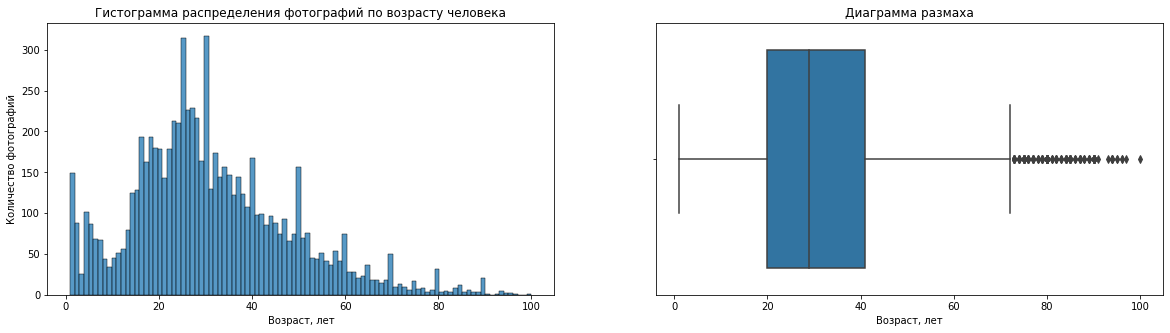

In [36]:
# построим распределение количества фотографий по возрасту человека 
# дополнительно построим диаграмму размаха
# число bins возьмем, равным 100 (максимум для real_age)
plt.figure(figsize=(20, 5))
plt.subplot(1, 2, 1)
plt.xlabel('Возраст, лет')
plt.ylabel('Количество фотографий')
plt.title('Гистограмма распределения фотографий по возрасту человека')
sns.histplot(data=df_labels, 
             x='real_age', 
             bins=100)
plt.subplot(1, 2, 2)
plt.xlabel('Возраст, лет')
plt.title('Диаграмма размаха')
sns.boxplot(x=df_labels['real_age'], data=df_labels)
plt.xlabel('Возраст, лет');

___
Для проверки нормальности распределения признаков мы вычислим критерии Шапиро — Уилка. Он нужен, чтобы оценивать нормальность распределения с помощью статистического показателя, а не графика. 

Нулевая гипотеза в критерии Шапиро — Уилка: переменная распределена нормально. Если мы получаем значение `p-value` больше 0.05, то мы не можем отклонить нулевую гипотезу. 
Альтернативная гипотеза: Если мы получаем значение `p-value` меньше 0.05, то данные не имеют нормального распределения.
___

In [52]:
# выполнение теста Шапиро-Уилка на нормальность распределения данных 
print('Результат выполнения теста Шапиро-Уилка на нормальность распределения данных:\n', 
      shapiro(df_labels['real_age']))

Результат выполнения теста Шапиро-Уилка на нормальность распределения данных:
 ShapiroResult(statistic=0.9651562571525574, pvalue=2.7277269529992235e-39)


/opt/conda/lib/python3.9/site-packages/scipy/stats/_morestats.py:1800: UserWarning: p-value may not be accurate for N > 5000.
  warnings.warn("p-value may not be accurate for N > 5000.")


___
**Вывод**

Успешно выполнили загрузку предоставленного набора данных из `labels.csv` в датафрейм `df_labels`. 

Выделим основные особенности:
- в датафрейме 7591 строка и 2 столбца:
    - `file_name` - наименование фотографии, содержащее шестизначный порядковый номер, начиная с 000000, и расширение файла (`.jpg`). Тип данных `object`
    - `real_age` - возраст человека на фотографии, указанный в годах. Тип данных `int64`
- Пропуски отсутствуют
- Аномальных значений возраста нет. Минимальное значение - 1 год, максимальное - 100 лет, среднее - 31 год, медианное - 29 лет. Половина людей на фотографиях имеют возраст от 20 до 41 года
- Распределение фотографий по возрасту не является нормальным, что подтверждает результат выполнения теста Шапиро-Уилка, где `p-value` меньше `0.05`. Основной пик распределения находится в диапазоне ~20-30 лет. Дополнительно, можно выделить еще несколько пиковых зон в распределении:
    - от ~1 до 7 лет;
    - отдельные всплески в значениях, кратных 10 в интервале с 30 до 90 лет. Что может быть следствием округлений в первичных данных

___

### Папка со всеми изображениями (`/final_files`) 

In [83]:
# получим список имен JPG-файлов в указанной папке
image_files = [f for f in os.listdir(path_faces_images) if f.endswith('.jpg')]
print(f'Количество JPG-файлов в указанной папке: {len(image_files)}')

Количество JPG-файлов в указанной папке: 7591


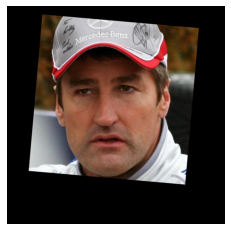

005226.jpg
Размеры изображения и цветовая модель: (787, 787), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
        file_name  real_age
5226  005226.jpg        43
--------------------------------------------------


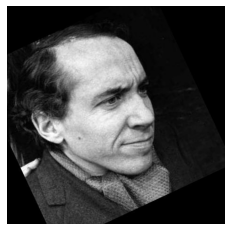

007426.jpg
Размеры изображения и цветовая модель: (462, 462), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
        file_name  real_age
7404  007426.jpg        44
--------------------------------------------------


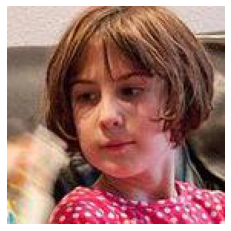

001184.jpg
Размеры изображения и цветовая модель: (142, 142), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
        file_name  real_age
1184  001184.jpg         6
--------------------------------------------------


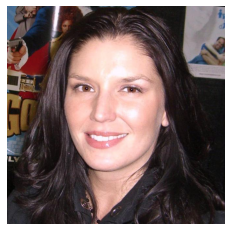

007520.jpg
Размеры изображения и цветовая модель: (669, 669), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
        file_name  real_age
7498  007520.jpg        34
--------------------------------------------------


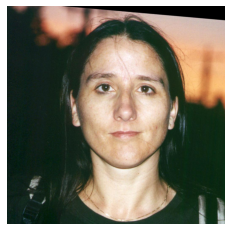

004415.jpg
Размеры изображения и цветовая модель: (1035, 1035), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
        file_name  real_age
4415  004415.jpg        39
--------------------------------------------------


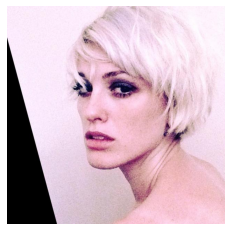

001798.jpg
Размеры изображения и цветовая модель: (630, 630), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
        file_name  real_age
1798  001798.jpg        27
--------------------------------------------------


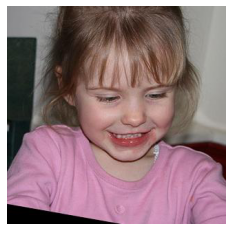

002797.jpg
Размеры изображения и цветовая модель: (318, 317), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
        file_name  real_age
2797  002797.jpg         2
--------------------------------------------------


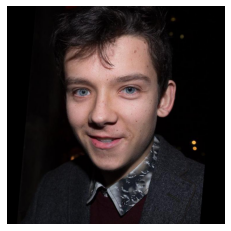

004223.jpg
Размеры изображения и цветовая модель: (747, 747), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
        file_name  real_age
4223  004223.jpg        17
--------------------------------------------------


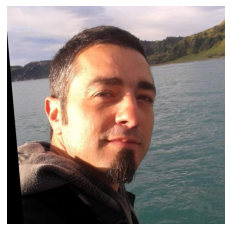

003420.jpg
Размеры изображения и цветовая модель: (632, 632), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
        file_name  real_age
3420  003420.jpg        37
--------------------------------------------------


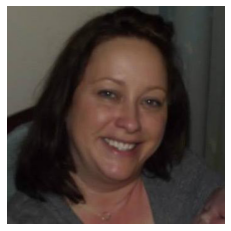

003067.jpg
Размеры изображения и цветовая модель: (350, 350), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
        file_name  real_age
3067  003067.jpg        39
--------------------------------------------------


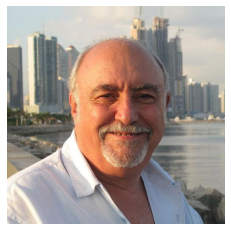

006282.jpg
Размеры изображения и цветовая модель: (554, 554), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
        file_name  real_age
6278  006282.jpg        68
--------------------------------------------------


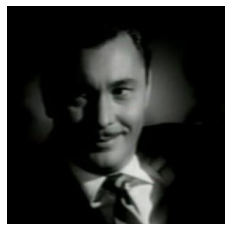

002022.jpg
Размеры изображения и цветовая модель: (311, 311), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
        file_name  real_age
2022  002022.jpg        40
--------------------------------------------------


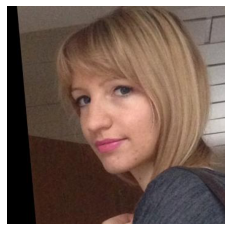

000578.jpg
Размеры изображения и цветовая модель: (355, 355), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
       file_name  real_age
578  000578.jpg        26
--------------------------------------------------


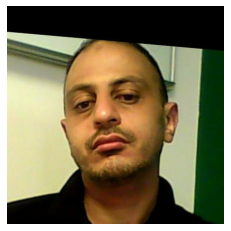

003646.jpg
Размеры изображения и цветовая модель: (430, 431), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
        file_name  real_age
3646  003646.jpg        43
--------------------------------------------------


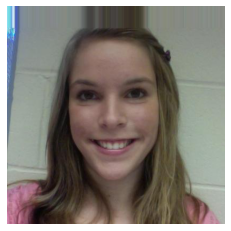

004896.jpg
Размеры изображения и цветовая модель: (408, 408), RGB
Количество каналов изображения: 3
Строка в файле labels.csv:
        file_name  real_age
4896  004896.jpg        17
--------------------------------------------------


In [84]:
# выведем первых 15 изображений из папки 
# добавим в вывод информацию о наименовании файла, размерах изображения в пикселях и цветовую модель  
# добавим в вывод соответствующую строчку по наименованию файла из labels.csv
for i in range(15):

    # полный путь к i-му изображению
    path_face_image = os.path.join(path_faces_images, image_files[i])
    # откроем изображение по указанному пути и сохраним его в переменную img в виде объекта Image
    img = Image.open(path_face_image)
    # преобразование в массив
    array = np.array(img)
    
    # выводим изображение на экран
    plt.imshow(array)
    # отключаем отображение осей координат на графике
    plt.axis('off')
    plt.show()
    
    # выводим информацию о наименовании файла, размерах изображения в пикселях и цветовую модель 
    print(file_image[i])
    print(f'Размеры изображения и цветовая модель: {img.size}, {img.mode}')
    print(f'Количество каналов изображения: {len(img.getbands())}')
    
    # выводим соответствующую строчку по наименованию файла из labels.csv
    print(f"Строка в файле labels.csv:\n {df_labels.loc[df_labels['file_name']==file_image[i]]}")
    
    print("-" * 50)


___
**Вывод по результатам анализа папки с изображениями**

- Папка `/final_files` содержит 7591 файл, формата `JPG` с изображением лиц людей разного возраста, пола, мимикой и с различным фоном
- Лица на фотографиях расположены по центру, размер лиц по отношению к общей площади фотографии достаточный
- Изображения квадратные, но с различными размерами в пикселях. 
- Цветовая модель `RGB` (3 канала)
- Фотографии размечены верно, возраст соответствует изображениям
___

## Обучение модели

*Код в этом разделе запускается в отдельном GPU-тренажёре, поэтому оформлен не как ячейка с кодом, а как код в текстовой ячейке*

- Будем использовать предобученную свёрточную нейронную сеть ResNet50.
- Изображения расположены в отдельных файлах формата `JPG`, для работы с ними будем использовать `ImageDataGenerator` и его метод `flow_from_dataframe`. При подготовке тренировочных данных будем использовать аугментацию: отражения, повороты, сдвиги.

### Код обучения модели

```python


import pandas as pd
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.optimizers import Adam


# Функция загрузки и подготовки тренировочных данных
def load_train(path):
    labels = pd.read_csv('/datasets/faces/labels.csv')
    # применяем загрузчик данных и аугментацию
    train_datagen = ImageDataGenerator(
        vertical_flip=True,
        horizontal_flip=True,
        rotation_range = 30,
        width_shift_range = 0.2,
        height_shift_range = 0.2,
        rescale=1./255,
        validation_split=.25
    )
    
    # вызываем извлечение данных из папки
    train_datagen_flow = train_datagen.flow_from_dataframe(
        dataframe = labels,
        directory='/datasets/faces/final_files/',
        x_col = 'file_name',
        y_col = 'real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='training',
        seed=12345)
    # результат: возвращение загрузчика данных тренировочной выборки
    return train_datagen_flow

# Функция загрузки и подготовки тестовых данных
def load_test(path):
    labels = pd.read_csv('/datasets/faces/labels.csv')
    # применяем загрузчик данных
    test_datagen = ImageDataGenerator(
        rescale=1./255,
        validation_split=.25
    )
    
    # вызываем извлечение данных из папки
    test_datagen_flow = test_datagen.flow_from_dataframe(
        dataframe = labels,
        directory='/datasets/faces/final_files/',
        x_col = 'file_name',
        y_col = 'real_age',
        target_size=(224, 224),
        batch_size=32,
        class_mode='raw',
        subset='validation',
        seed=12345)
    # результат: возвращение загрузчика данных тренировочной выборки
    return test_datagen_flow

# Функция создания модели нейросети
def create_model(input_shape):
    # добавляем архитектуру ResNet
    # тело архитектуры ResNet
    backbone = ResNet50(input_shape=(224, 224, 3),  
                        weights='/datasets/keras_models/resnet50_weights_tf_dim_ordering_tf_kernels_notop.h5', 
                        include_top=False)
    
    # Замораживаем все слои по умолчанию
    #for layer in backbone.layers:
    #    layer.trainable = False

    # Размораживаем последние 10 слоев (Индексация слоев начинается с 0)
    #for layer in backbone.layers[-10:]:
    #    layer.trainable = True    
    
    
    # инициализация модели
    model = Sequential()
    # добавление слоёв в модель
    # добавляем "тело" архитектуры ResNet    
    model.add(backbone)
    # добавляем глобальный пуллинг    
    model.add(GlobalAveragePooling2D())
    # добавляем полносвязный слой с 1 нейроном    
    #model.add(Dense(1, activation='relu'))
    model.add(Dense(1, activation='linear')) 
    # подготовка модели к обучению
    optimizer = Adam(learning_rate=1e-5)
    model.compile(optimizer=optimizer,
                  loss='mean_squared_error',
                  metrics=['mean_absolute_error'])
    # результат: возвращение настроенной модели
    return model

# Обучение модели
def train_model(model, train_data, test_data, batch_size=None, epochs=15,
               steps_per_epoch=None, validation_steps=None):

    train_datagen_flow = train_data
    test_datagen_flow = test_data
    
    # обучение модели
    model.fit(train_data,  
              validation_data=test_data,
              batch_size=batch_size, 
              epochs=epochs,
              steps_per_epoch=steps_per_epoch,
              validation_steps=validation_steps,
              verbose=2, 
              shuffle=True)
    # результат: возвращение обученной модели
    return model

```

### Результат вывода на экран


```


2025-12-03 08:46:48.716298: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libnvinfer.so.6
2025-12-03 08:46:48.718819: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libnvinfer_plugin.so.6
2025-12-03 08:46:49.592115: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcuda.so.1
2025-12-03 08:46:49.673599: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1555] Found device 0 with properties: 
pciBusID: 0000:8b:00.0 name: Tesla V100-SXM2-32GB computeCapability: 7.0
coreClock: 1.53GHz coreCount: 80 deviceMemorySize: 31.74GiB deviceMemoryBandwidth: 836.37GiB/s
2025-12-03 08:46:49.673659: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcudart.so.10.1
2025-12-03 08:46:49.673691: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcublas.so.10
2025-12-03 08:46:49.675957: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcufft.so.10
2025-12-03 08:46:49.676419: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcurand.so.10
2025-12-03 08:46:49.678864: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcusolver.so.10
2025-12-03 08:46:49.680236: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcusparse.so.10
2025-12-03 08:46:49.680295: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcudnn.so.7
2025-12-03 08:46:49.681427: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1697] Adding visible gpu devices: 0
Using TensorFlow backend.
Found 5694 validated image filenames.
Found 1897 validated image filenames.
2025-12-03 08:46:49.856607: I tensorflow/core/platform/cpu_feature_guard.cc:142] Your CPU supports instructions that this TensorFlow binary was not compiled to use: AVX2 AVX512F FMA
2025-12-03 08:46:49.863403: I tensorflow/core/platform/profile_utils/cpu_utils.cc:94] CPU Frequency: 2099990000 Hz
2025-12-03 08:46:49.864076: I tensorflow/compiler/xla/service/service.cc:168] XLA service 0x422f7420 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
2025-12-03 08:46:49.864103: I tensorflow/compiler/xla/service/service.cc:176]   StreamExecutor device (0): Host, Default Version
2025-12-03 08:46:49.980309: I tensorflow/compiler/xla/service/service.cc:168] XLA service 0x41b63fa0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2025-12-03 08:46:49.980349: I tensorflow/compiler/xla/service/service.cc:176]   StreamExecutor device (0): Tesla V100-SXM2-32GB, Compute Capability 7.0
2025-12-03 08:46:49.981183: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1555] Found device 0 with properties: 
pciBusID: 0000:8b:00.0 name: Tesla V100-SXM2-32GB computeCapability: 7.0
coreClock: 1.53GHz coreCount: 80 deviceMemorySize: 31.74GiB deviceMemoryBandwidth: 836.37GiB/s
2025-12-03 08:46:49.981236: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcudart.so.10.1
2025-12-03 08:46:49.981247: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcublas.so.10
2025-12-03 08:46:49.981273: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcufft.so.10
2025-12-03 08:46:49.981283: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcurand.so.10
2025-12-03 08:46:49.981293: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcusolver.so.10
2025-12-03 08:46:49.981303: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcusparse.so.10
2025-12-03 08:46:49.981311: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcudnn.so.7
2025-12-03 08:46:49.982624: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1697] Adding visible gpu devices: 0
2025-12-03 08:46:49.982683: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcudart.so.10.1
2025-12-03 08:46:50.323030: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1096] Device interconnect StreamExecutor with strength 1 edge matrix:
2025-12-03 08:46:50.323080: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1102]      0 
2025-12-03 08:46:50.323089: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1115] 0:   N 
2025-12-03 08:46:50.324275: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:39] Overriding allow_growth setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
2025-12-03 08:46:50.324317: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1241] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 10240 MB memory) -> physical GPU (device: 0, name: Tesla V100-SXM2-32GB, pci bus id: 0000:8b:00.0, compute capability: 7.0)
<class 'tensorflow.python.keras.engine.sequential.Sequential'>
WARNING:tensorflow:sample_weight modes were coerced from
  ...
    to  
  ['...']
WARNING:tensorflow:sample_weight modes were coerced from
  ...
    to  
  ['...']
Train for 178 steps, validate for 60 steps
Epoch 1/15
2025-12-03 08:47:00.381863: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcublas.so.10
2025-12-03 08:47:00.877532: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcudnn.so.7
178/178 - 104s - loss: 858.7393 - mean_absolute_error: 24.7186 - val_loss: 1049.8361 - val_mean_absolute_error: 27.7679
Epoch 2/15
178/178 - 92s - loss: 305.8921 - mean_absolute_error: 13.7700 - val_loss: 1003.3739 - val_mean_absolute_error: 26.9624
Epoch 3/15
178/178 - 94s - loss: 176.6982 - mean_absolute_error: 10.0555 - val_loss: 937.0235 - val_mean_absolute_error: 25.7092
Epoch 4/15
178/178 - 94s - loss: 133.6927 - mean_absolute_error: 8.7054 - val_loss: 210.4451 - val_mean_absolute_error: 10.6030
Epoch 5/15
178/178 - 94s - loss: 116.4993 - mean_absolute_error: 8.1886 - val_loss: 115.2898 - val_mean_absolute_error: 8.0661
Epoch 6/15
178/178 - 94s - loss: 102.2857 - mean_absolute_error: 7.7098 - val_loss: 95.0383 - val_mean_absolute_error: 7.2989
Epoch 7/15
178/178 - 95s - loss: 95.6693 - mean_absolute_error: 7.4769 - val_loss: 99.5837 - val_mean_absolute_error: 7.4316
Epoch 8/15
178/178 - 95s - loss: 89.5134 - mean_absolute_error: 7.2406 - val_loss: 89.3990 - val_mean_absolute_error: 7.0215
Epoch 9/15
178/178 - 95s - loss: 85.5157 - mean_absolute_error: 7.0757 - val_loss: 118.6903 - val_mean_absolute_error: 8.1061
Epoch 10/15
178/178 - 96s - loss: 81.5854 - mean_absolute_error: 6.9102 - val_loss: 91.7417 - val_mean_absolute_error: 7.0261
Epoch 11/15
178/178 - 95s - loss: 76.6746 - mean_absolute_error: 6.7327 - val_loss: 88.6160 - val_mean_absolute_error: 7.0148
Epoch 12/15
178/178 - 95s - loss: 73.5163 - mean_absolute_error: 6.5768 - val_loss: 88.3844 - val_mean_absolute_error: 6.9588
Epoch 13/15
178/178 - 95s - loss: 68.1824 - mean_absolute_error: 6.2872 - val_loss: 88.2336 - val_mean_absolute_error: 6.9845
Epoch 14/15
178/178 - 95s - loss: 66.3059 - mean_absolute_error: 6.2733 - val_loss: 87.3410 - val_mean_absolute_error: 6.9017
Epoch 15/15
178/178 - 95s - loss: 63.6420 - mean_absolute_error: 6.1335 - val_loss: 88.0480 - val_mean_absolute_error: 6.9217
WARNING:tensorflow:sample_weight modes were coerced from
  ...
    to  
  ['...']
60/60 - 10s - loss: 88.0480 - mean_absolute_error: 6.9217
Test MAE: 6.9217 

```

## Анализ обученной модели и выводы

В данном проекте мы разработали и обучили нейронную сеть, способную решить задачу регрессии и определить возраст человека по фотографии:
- Использована предобученная модель `ResNet50` c соответствующей архитектурой.
- Значение метрики качества `MAE` на тестовой выборке составило `6.92`, что соответствует требованиям Заказчика (не больше 8). 

Полученное значение метрики качества означает, что данная модель ошибается в определении возраста человека по его фотографии в среднем на ~7 лет. Если в целях формирования предложений по товарам для возрастных групп это не критично, то для целей контроля добросовестности кассиров при продаже алкоголя это довольно много. Улучшить качество предсказаний модели нам помогло бы следующее:
- получить больше размеченых фотографий по людям для возрастных интервалов до 20 и старше 42 лет
- проверить и уточнить разметку фотографий по людям, у которых указан возраст, кратный 10 в интервале 30-90 лет
- можно попробовать увеличить количество эпох, так как в текущей реализации признаков переобучения модели не наблюдается

## Чек-лист

- [x]  Jupyter Notebook открыт
- [x]  Весь код выполняется без ошибок
- [x]  Ячейки с кодом расположены в порядке исполнения
- [x]  Исследовательский анализ данных выполнен
- [x]  Результаты исследовательского анализа данных перенесены в финальную тетрадь
- [x]  MAE модели не больше 8
- [x]  Код обучения модели скопирован в финальную тетрадь
- [x]  Результат вывода модели на экран перенесён в финальную тетрадь
- [x]  По итогам обучения модели сделаны выводы